In [418]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [419]:
import pandas as pd
from matplotlib import pyplot as plt

# Replace 'path/to/your/file.csv' with the actual path to your CSV file in Google Drive
csv_file_path = '/content/drive/MyDrive/Colab Notebooks/loan_data.csv'
df = pd.read_csv(csv_file_path)

In [420]:
# Display the first 5 rows of the DataFrame
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22,female,Master,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,female,High School,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,male,Master,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1


In [421]:
t = df.shape # returns a tuple = (Rows, Columns)
rows = t[0]
cols = t[1]
print(f"Rows: {rows} Columns: {cols}")

Rows: 45000 Columns: 14


In [422]:
df.info() #It provides a concise summary of a DataFrame's structure.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  int64  
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  int64  
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  int64  
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  int64  
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

NO NULL VALUE PRESENT

In [423]:
d = df.duplicated().sum()
print(f"{d} duplicate values found in the dataset")

0 duplicate values found in the dataset


In [424]:
df2 = df.drop(["person_gender","person_education","person_age"],axis = 1)
df2.head(5)

,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1


### CHECKING FOR CLASS BALANCE

In [425]:
df2["loan_status"].value_counts(normalize=True)

,proportion
loan_status,
0,0.777778
1,0.222222


## Outlier Detection

In [426]:
df2['person_emp_exp'].unique()

array([  0,   3,   1,   5,   4,   2,   7,   6, 125,   8, 121, 101, 100,
        12,  10,   9,  14,  13,  11,  15,  16,  17,  19,  28,  25,  18,
        24,  22,  20,  23,  21,  31,  26,  27,  29,  32,  30, 124,  40,
        43,  33,  44,  34,  42,  37,  45,  36,  41,  47,  38,  39,  35,
        57,  46,  49,  48,  50,  76,  62,  61,  58,  93,  85])

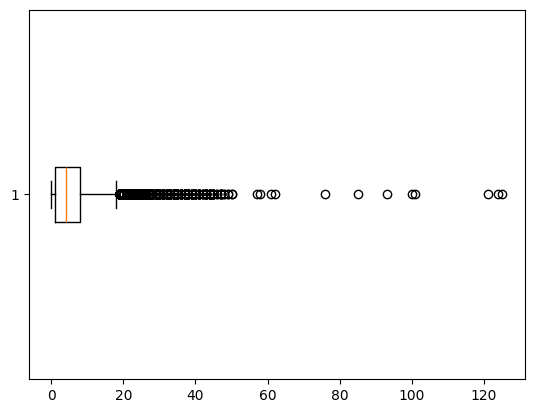

In [427]:
plt.boxplot(df2['person_emp_exp'],orientation = 'horizontal')
plt.show()

In [428]:
df3 = df2[df2['person_emp_exp'] <= 40] ## Only rows which has experience less than or equal to 40 are kept.

## Perform Label Encoding

In [429]:
df2["person_home_ownership"].unique()

array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

In [430]:
df2["previous_loan_defaults_on_file"].unique()

array(['No', 'Yes'], dtype=object)

In [431]:
df2["loan_intent"].unique()

array(['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT',
       'DEBTCONSOLIDATION'], dtype=object)

In [432]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df3["person_home_ownership"] = le.fit_transform(df3["person_home_ownership"])
df3["loan_intent"] = le.fit_transform(df3["loan_intent"])
df3["previous_loan_defaults_on_file"] = le.fit_transform(df3["previous_loan_defaults_on_file"])
df3.head(5)

/tmp/ipykernel_2349/4028508568.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["person_home_ownership"] = le.fit_transform(df3["person_home_ownership"])
/tmp/ipykernel_2349/4028508568.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["loan_intent"] = le.fit_transform(df3["loan_intent"])
/tmp/ipykernel_2349/4028508568.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the d

,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,71948,0,3,35000,4,16.02,0.49,3,561,0,1
1,12282,0,2,1000,1,11.14,0.08,2,504,1,0
2,12438,3,0,5500,3,12.87,0.44,3,635,0,1
3,79753,0,3,35000,3,15.23,0.44,2,675,0,1
4,66135,1,3,35000,3,14.27,0.53,4,586,0,1


In [433]:
y = df3["loan_status"]
x = df3.drop("loan_status",axis = 1)

## Split dataset into Training and Testing data

In [434]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y
)

stratify makes the train and test sets keep the same class proportions as the original data.   
In your loan dataset (77% Class 0 and 23% Class 1), passing stratify=y guarantees that both y_train and y_test end up with that exact 77% / 23% split, rather than leaving the ratio up to random chance.

In [435]:
print(f"Train data rows: {x_train.shape[0]}")
print(f"Test data rows: {x_test.shape[0]}")

Train data rows: 35948
Test data rows: 8987


# Perform Standardization (scaling)

In [436]:
from sklearn.preprocessing import StandardScaler

cols = ["person_income", "loan_amnt", "credit_score"]

scaler = StandardScaler()
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[cols] = scaler.fit_transform(x_train[cols])
x_test_scaled[cols] = scaler.transform(x_test[cols])


**fit_transform on x_train[cols]:** calculates the mean and standard deviation of these three columns from the training set, and immediately standardizes them.

**x_test.loc[:, cols] = scaler.transform(x_test[cols]):**

transform scales the test set columns using the same mean and standard deviation computed from the training set.
This prevents 'data leakage', ensuring your model is evaluated under realistic conditions without knowing anything about the distribution of the test set beforehand.



**Importing all supervised classification algorithm**



In [437]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## **Initialising Models here**




In [438]:
models = ["LogisticRegression" , "KNN" , "ID3", "CART" , "MLP" , "Naive"]

In [439]:
logistic = LogisticRegression()
knn = KNeighborsClassifier(n_neighbors=4, metric="manhattan")
naive = GaussianNB()
mlp = MLPClassifier(
    hidden_layer_sizes=(64,32),
    max_iter=2000,
    activation = 'relu',
    solver='adam',
    shuffle=True,
    learning_rate_init=0.001,
    random_state=42
    )
id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    max_depth = 6
)
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    max_depth = 6
)

**Train all supervised classification algorithm**

---



In [440]:
logistic.fit(x_train,y_train)
knn.fit(x_train_scaled,y_train)
naive.fit(x_train,y_train)
id3_model.fit(x_train, y_train)
cart_model.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


DecisionTreeClassifier(max_depth=6, random_state=42)

In [441]:
mlp.fit(x_train_scaled,y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42)

**Perform prediction using all supervised classification algorithm**

In [458]:
predictions_of_logistic = logistic.predict(x_test)
predictions_of_knn = knn.predict(x_test_scaled)
predictions_of_naive = naive.predict(x_test)
id3_predictions = id3_model.predict(x_test)
cart_predictions = cart_model.predict(x_test)
predictions_of_mlp = mlp.predict(x_test_scaled)

**Print accuracy all supervised classification algorithm**

In [443]:
logistic_accuracy = accuracy_score(y_test, predictions_of_logistic)*100
knn_accuracy = accuracy_score(y_test, predictions_of_knn)*100
naive_accuracy = accuracy_score(y_test, predictions_of_naive)*100
id3_accuracy = accuracy_score(y_test, id3_predictions)*100
cart_accuracy = accuracy_score(y_test, cart_predictions)*100
mlp_accuracy = accuracy_score(y_test, predictions_of_mlp)*100

**VISUALIZE ACCURACY**

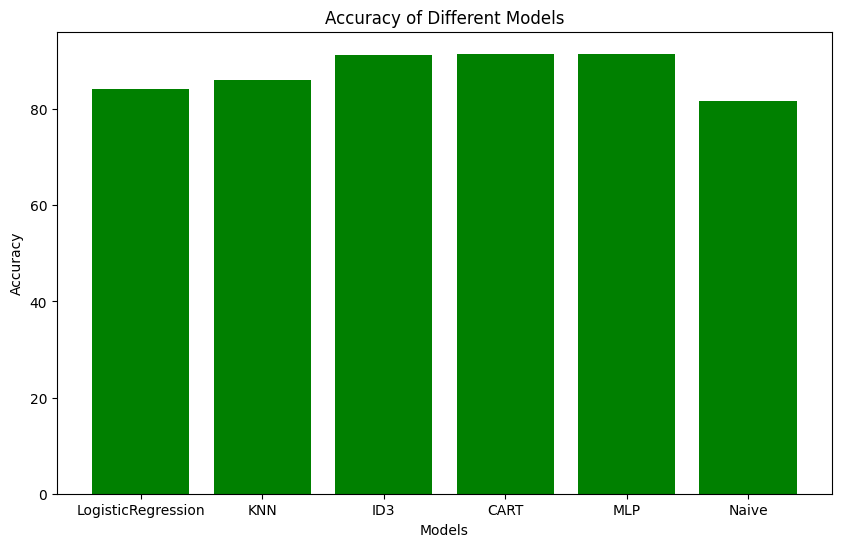

In [444]:
accuracy_list = [logistic_accuracy , knn_accuracy , id3_accuracy , cart_accuracy , mlp_accuracy , naive_accuracy]

plt.figure(figsize=(10, 6))
plt.bar(models,accuracy_list,color="green")
plt.title("Accuracy of Different Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

GET CLASSIFICATION REPORT

In [445]:
logistic_report = classification_report(y_test, predictions_of_logistic)
knn_report = classification_report(y_test, predictions_of_knn)
naive_report = classification_report(y_test, predictions_of_naive)
naive_scaled_report = classification_report(y_test, predictions_of_naive_scaled)
id3_report = classification_report(y_test, id3_predictions)
cart_report = classification_report(y_test, cart_predictions)
mlp_report = classification_report(y_test, predictions_of_mlp)

**EVALUATE PRECISION , RECALL and F1 score OF ALL MODELS**

In [446]:
from sklearn.metrics import precision_score, recall_score, f1_score

## Precision

logistic_precison = precision_score(y_test,predictions_of_logistic,pos_label=1)
# pos_label	Which class counts as positive in binary problems (default 1)
knn_precision = precision_score(y_test,predictions_of_knn,pos_label=1)
naive_precision = precision_score(y_test,predictions_of_naive,pos_label=1)
naive_scaled_precision = precision_score(y_test,predictions_of_naive_scaled,pos_label=1)
id3_precision = precision_score(y_test,id3_predictions,pos_label=1)
cart_precision = precision_score(y_test,cart_predictions,pos_label=1)
mlp_precision = precision_score(y_test,predictions_of_mlp,pos_label=1)

## F1 Score

logistic_f1 = f1_score(y_test,predictions_of_logistic,pos_label=1)
knn_f1 = f1_score(y_test,predictions_of_knn,pos_label=1)
naive_f1 = f1_score(y_test,predictions_of_naive,pos_label=1)
naive_scaled_f1 = f1_score(y_test,predictions_of_naive_scaled,pos_label=1)
id3_f1 = f1_score(y_test,id3_predictions,pos_label=1)
cart_f1 = f1_score(y_test,cart_predictions,pos_label=1)
mlp_f1 = f1_score(y_test,predictions_of_mlp,pos_label=1)

## Recall

logistic_recall = recall_score(y_test,predictions_of_logistic,pos_label=1)
knn_recall = recall_score(y_test,predictions_of_knn,pos_label=1)
naive_recall = recall_score(y_test,predictions_of_naive,pos_label=1)
naive_scaled_recall = recall_score(y_test,predictions_of_naive,pos_label=1)
id3_recall = recall_score(y_test,id3_predictions,pos_label=1)
cart_recall = recall_score(y_test,cart_predictions,pos_label=1)
mlp_recall = recall_score(y_test,predictions_of_mlp,pos_label=1)



**Confusion Matrix of Logistic Regression**

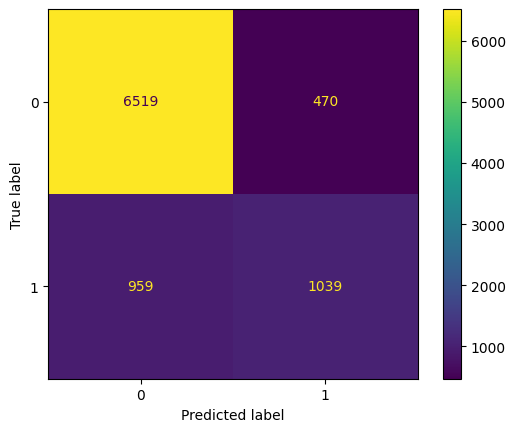

In [447]:
cml = confusion_matrix(y_test, predictions_of_logistic)
ConfusionMatrixDisplay(cml).plot()

**Confusion Matrix of KNN**

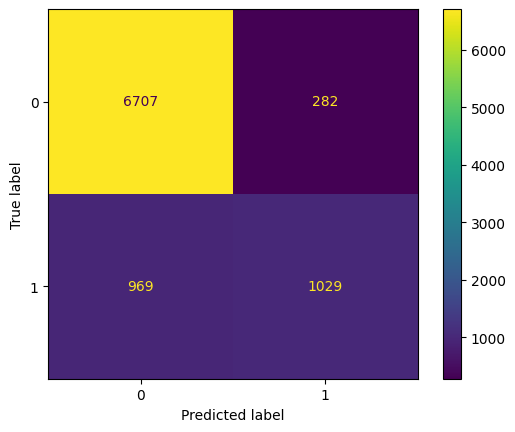

In [448]:
cmk = confusion_matrix(y_test, predictions_of_knn)
ConfusionMatrixDisplay(cmk).plot()

**Confusion Matrix of Decision Tree**

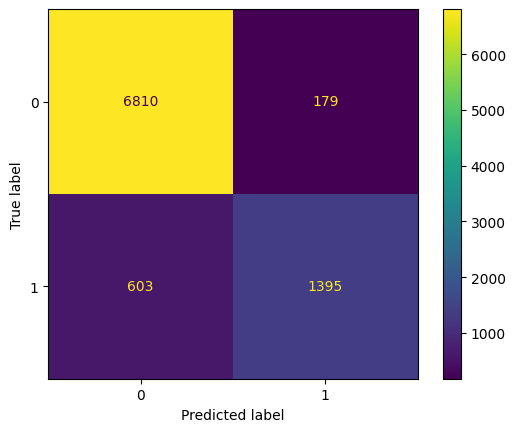

In [449]:
cmd = confusion_matrix(y_test, id3_predictions)
ConfusionMatrixDisplay(cmd).plot()

**Confusion Matrix of Naive Classifier**

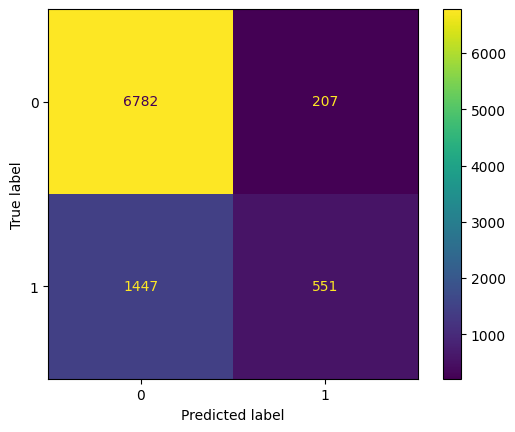

In [450]:
cmn = confusion_matrix(y_test, predictions_of_naive)
ConfusionMatrixDisplay(cmn).plot()

**Confusion Matrix of Multi layer perceptron**

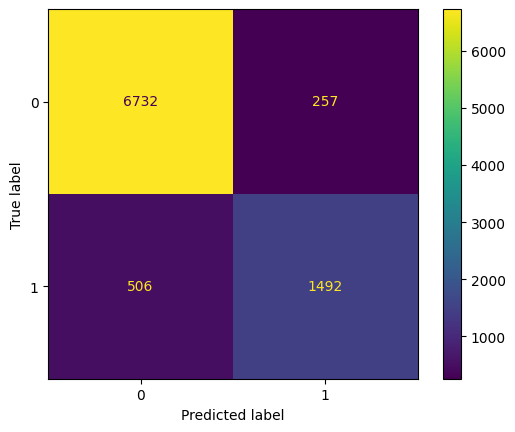

In [451]:
cmm = confusion_matrix(y_test, predictions_of_mlp)
ConfusionMatrixDisplay(cmm).plot()

**Computing Prediction scores**

In [452]:
logistic_score = logistic.predict_proba(x_test)[:,1]
knn_score = knn.predict_proba(x_test_scaled)[:,1]
naive_score = naive.predict_proba(x_test)[:,1]
id3_score = id3_model.predict_proba(x_test)[:,1]
cart_score = cart_model.predict_proba(x_test)[:,1]
mlp_score = mlp.predict_proba(x_test_scaled)[:,1]

predict_proba returns the model's confidence for each class, as probabilities, instead of a single final answer.

predict(X) -The final class - label	1  
predict_proba(X)- Probability of each class	- [0.2, 0.8]    
predict internally just takes the class with the higher probability (for binary, it applies a 0.5 cutoff). predict_proba gives you the raw confidence before that cutoff is applied.  
A 2D array (NumPy) with one row per sample and one column per class.   
Each row sums to 1.  
array([[class 0, class 1] - [0.90, 0.10],
       [0.30, 0.70],
       [0.55, 0.45],
       [0.05, 0.95]])
We only take probability of column 1 and all rows.  
For binary problems the two columns are redundant: P(class 0) = 1 - P(class 1). roc_auc_score needs one score per sample, where a higher score means "more likely positive." The positive-class probability is exactly that.

In [453]:
from sklearn.metrics import roc_auc_score

logistic_auc = roc_auc_score(y_test, logistic_score)
knn_auc = roc_auc_score(y_test, knn_score)
naive_auc = roc_auc_score(y_test, naive_score)
id3_auc = roc_auc_score(y_test, id3_score)
cart_auc = roc_auc_score(y_test, cart_score)
mlp_auc = roc_auc_score(y_test, mlp_score)

**Computing AUC score for each model**

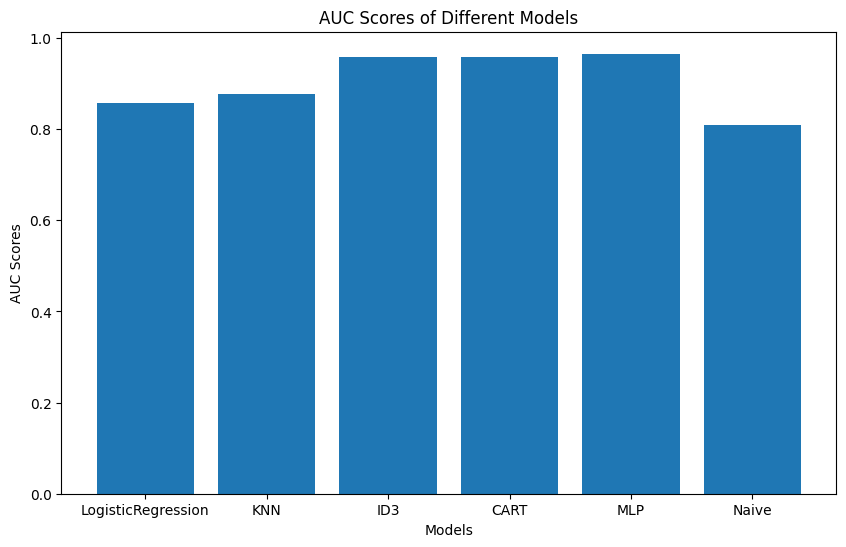

In [454]:
auc_scores = [logistic_auc, knn_auc, id3_auc, cart_auc, mlp_auc, naive_auc]

plt.figure(figsize=(10, 6))
plt.bar(models,auc_scores)
plt.title("AUC Scores of Different Models")
plt.xlabel("Models")
plt.ylabel("AUC Scores")
plt.show()

In [455]:
report = {
    "Logistic Regression": {
        "Accuracy": round(logistic_accuracy, 3),
        "Precision": round(logistic_precison, 3),
        "Recall": round(logistic_recall, 3),
        "F1 Score": round(logistic_f1, 3),
        "AUC": round(float(logistic_auc), 3),
    },
    "KNN": {
        "Accuracy": round(knn_accuracy, 3),
        "Precision": round(knn_precision, 3),
        "Recall": round(knn_recall, 3),
        "F1 Score": round(knn_f1, 3),
        "AUC": round(float(knn_auc), 3),
    },
    "Naive Bayes": {
        "Accuracy": round(naive_accuracy, 3),
        "Precision": round(naive_precision, 3),
        "Recall": round(naive_recall, 3),
        "F1 Score": round(naive_f1, 3),
        "AUC": round(float(naive_auc), 3),
    },
    "ID3": {
        "Accuracy": round(id3_accuracy, 3),
        "Precision": round(id3_precision, 3),
        "Recall": round(id3_recall, 3),
        "F1 Score": round(id3_f1, 3),
        "AUC": round(float(id3_auc), 3),
    },
    "CART": {
        "Accuracy": round(cart_accuracy, 3),
        "Precision": round(cart_precision, 3),
        "Recall": round(cart_recall, 3),
        "F1 Score": round(cart_f1, 3),
        "AUC": round(float(cart_auc), 3),
    },
    "MLP": {
        "Accuracy": round(mlp_accuracy, 3),
        "Precision": round(mlp_precision, 3),
        "Recall": round(mlp_recall, 3),
        "F1 Score": round(mlp_f1, 3),
        "AUC": round(float(mlp_auc), 3),
    },
}

**Displaying ROC-AUC CURVE**

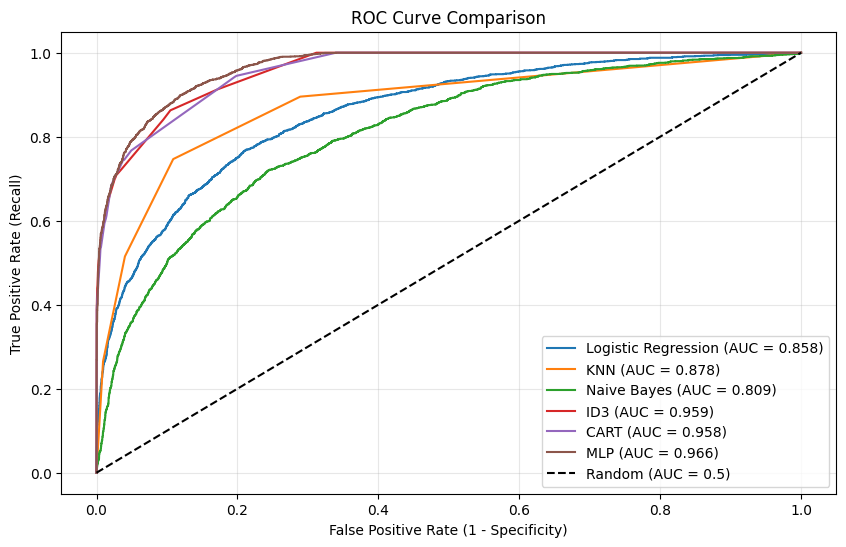

In [456]:
from sklearn.metrics import roc_curve

scores = {
    "Logistic Regression": logistic_score,
    "KNN": knn_score,
    "Naive Bayes": naive_score,
    "ID3": id3_score,
    "CART": cart_score,
    "MLP": mlp_score,
}

fig = plt.subplots(figsize=(10, 6))

for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [457]:
print("FINAL RESULT\n")
print("Logistic Regression: ",report["Logistic Regression"])
print("KNN: ",report["KNN"])
print("Naive Bayes: ",report["Naive Bayes"])
print("ID3: ",report["ID3"])
print("CART: ",report["CART"])
print("MLP: ",report["MLP"])

FINAL RESULT

Logistic Regression:  {'Accuracy': 84.099, 'Precision': 0.689, 'Recall': 0.52, 'F1 Score': 0.593, 'AUC': 0.858}
KNN:  {'Accuracy': 86.08, 'Precision': 0.785, 'Recall': 0.515, 'F1 Score': 0.622, 'AUC': 0.878}
Naive Bayes:  {'Accuracy': 81.596, 'Precision': 0.727, 'Recall': 0.276, 'F1 Score': 0.4, 'AUC': 0.809}
ID3:  {'Accuracy': 91.299, 'Precision': 0.886, 'Recall': 0.698, 'F1 Score': 0.781, 'AUC': 0.959}
CART:  {'Accuracy': 91.41, 'Precision': 0.881, 'Recall': 0.709, 'F1 Score': 0.786, 'AUC': 0.958}
MLP:  {'Accuracy': 91.51, 'Precision': 0.853, 'Recall': 0.747, 'F1 Score': 0.796, 'AUC': 0.966}




1.   MLP, CART, and ID3 clearly outperform KNN, Logistic Regression, and Naive Bayes on every metric.
2.   MLP performs best overall, with the highest accuracy, recall, F1, and AUC.

**Select the MLP as the best-performing model**

